Generowanie maski uwagi NIST...
✅ Maska gotowa i zapisana jako 'nist_attention_mask.npy'!


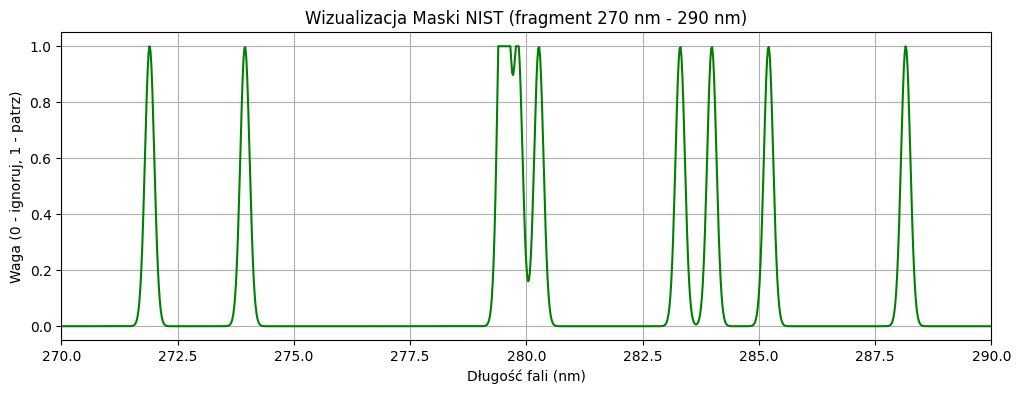

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definicja osi X (Wavelengths) ze Springera
# Zakładamy 40002 punkty dla bezpieczeństwa Twojego wymiaru wejściowego
wavelengths = np.linspace(200, 1000, 40002)

# 2. Baza NIST (Matryca Wiedzy)
# Wpisałem tu dla Ciebie najsilniejsze, najbardziej znane linie dla głównych pierwiastków.
# ZADANIE DLA CIEBIE: Możesz śmiało rozszerzyć te listy na podstawie pełnej bazy NIST.
nist_lines = {
    'Fe': [259.94, 271.90, 273.95, 404.58, 438.35],
    'Mg': [279.55, 280.27, 285.21, 516.73, 517.27, 518.36],
    'Cu': [324.75, 327.40, 510.55, 521.82],
    'Al': [308.21, 309.27, 394.40, 396.15],
    'Ca': [315.88, 317.93, 393.36, 396.84, 422.67],
    'Si': [251.61, 252.85, 288.16],
    'Ti': [334.94, 336.12, 365.35, 399.86],
    'Na': [588.99, 589.59],
    'K':  [766.49, 769.89],
    'Mn': [257.61, 259.37, 279.48, 279.82, 403.07],
    # Powietrze uwięzione w plazmie (świetny wzorzec tła)
    'O':  [777.19, 777.41, 777.53, 844.63], 
    'N':  [742.36, 744.23, 746.83, 821.63],
    # Reszta unikalnych pierwiastków z tabeli:
    'Pb': [220.35, 283.31, 368.35, 405.78],
    'Zn': [202.54, 206.20, 213.86, 330.26, 481.05],
    'Ag': [328.07, 338.29],
    'Ni': [231.60, 232.00, 341.48, 352.45],
    'Sn': [283.99, 317.51, 326.23],
    'Au': [242.80, 267.59],
    'W':  [400.87, 429.46, 430.21],
    'Cr': [357.87, 359.35, 425.43, 427.48, 428.97],
    'U':  [358.49, 385.96, 386.18, 409.01]
}

# 3. Parametry fizyczne maski
sigma = 0.10  # Otwieramy "okno" tolerancji na ok. 5 punktów osi X w obie strony

# 4. Generowanie pustego płótna (wszędzie 0 - czarna maska)
attention_mask = np.zeros_like(wavelengths)

# 5. Malowanie Gaussią (wycinanie dziur w masce dla światła)
print("Generowanie maski uwagi NIST...")
for element, lines in nist_lines.items():
    for line in lines:
        if 200 <= line <= 1000:
            # Wzmocnienie Gaussa w miejscu linii
            attention_mask += np.exp(-((wavelengths - line)**2) / (2 * sigma**2))

# 6. Normalizacja maski - upewniamy się, że nie przekracza 1.0 (100% sygnału)
attention_mask = np.clip(attention_mask, 0.0, 1.0)

# Opcjonalnie: Zapis maski do pliku na dysk
np.save('nist_attention_mask.npy', attention_mask)
print("✅ Maska gotowa i zapisana jako 'nist_attention_mask.npy'!")

# --- WIZUALIZACJA ---
# Zobaczmy, co wygenerowaliśmy, na przykładzie fragmentu z żelazem i magnezem (275-285 nm)
plt.figure(figsize=(12, 4))
plt.plot(wavelengths, attention_mask, color='green')
plt.xlim(270, 290)
plt.title("Wizualizacja Maski NIST (fragment 270 nm - 290 nm)")
plt.xlabel("Długość fali (nm)")
plt.ylabel("Waga (0 - ignoruj, 1 - patrz)")
plt.grid(True)
plt.show()

In [3]:
import h5py

def print_h5_structure(h5_obj, indent=""):
    """Rekurencyjnie wypisuje strukturę pliku HDF5."""
    for key, item in h5_obj.items():
        if isinstance(item, h5py.Group):
            print(f"{indent}Grupa: {key}")
            print_h5_structure(item, indent + "  ")
        elif isinstance(item, h5py.Dataset):
            print(f"{indent}Dataset: {key} | Kształt: {item.shape} | Typ: {item.dtype}")

# Zmień ścieżkę, jeśli plik train.h5 nie jest w tym samym folderze
with h5py.File('train.h5', 'r') as f:
    print("--- Struktura pliku train.h5 ---")
    print_h5_structure(f)

--- Struktura pliku train.h5 ---
Grupa: Class
  Dataset: 1 | Kształt: (50000,) | Typ: float64
Grupa: Spectra
  Dataset: 001 | Kształt: (40002, 500) | Typ: float64
  Dataset: 002 | Kształt: (40002, 500) | Typ: float64
  Dataset: 003 | Kształt: (40002, 500) | Typ: float64
  Dataset: 004 | Kształt: (40002, 500) | Typ: float64
  Dataset: 005 | Kształt: (40002, 500) | Typ: float64
  Dataset: 006 | Kształt: (40002, 500) | Typ: float64
  Dataset: 007 | Kształt: (40002, 500) | Typ: float64
  Dataset: 008 | Kształt: (40002, 500) | Typ: float64
  Dataset: 009 | Kształt: (40002, 500) | Typ: float64
  Dataset: 010 | Kształt: (40002, 500) | Typ: float64
  Dataset: 011 | Kształt: (40002, 500) | Typ: float64
  Dataset: 012 | Kształt: (40002, 500) | Typ: float64
  Dataset: 013 | Kształt: (40002, 500) | Typ: float64
  Dataset: 014 | Kształt: (40002, 500) | Typ: float64
  Dataset: 015 | Kształt: (40002, 500) | Typ: float64
  Dataset: 016 | Kształt: (40002, 500) | Typ: float64
  Dataset: 017 | Kształt: (

In [8]:
import h5py
import numpy as np
import scipy.ndimage as ndimage
from tqdm import tqdm

# --- USTAWIENIA ---
INPUT_H5 = 'train.h5'                    
OUTPUT_H5 = 'train_nist_cleaned_1.h5'      
MASK_FILE = 'nist_attention_mask.npy'    
WINDOW_SIZE = 100 

print("1. Ładowanie Maski NIST...")
nist_mask = np.load(MASK_FILE)

print(f"2. Tworzenie nowej bazy zoptymalizowanej dla AI: {OUTPUT_H5}")
with h5py.File(INPUT_H5, 'r') as f_in, h5py.File(OUTPUT_H5, 'w') as f_out:
    
    # Krok A: Kopiujemy etykiety klas
    print("Kopiowanie etykiet klas...")
    f_out.create_dataset('Class/1', data=f_in['Class/1'][:], compression="gzip")
    
    # Krok B: Kopiujemy oś długości fal (bonus ze struktury!)
    print("Kopiowanie osi długości fal (Wavelengths)...")
    if 'Wavelengths/1' in f_in:
        f_out.create_dataset('Wavelengths/1', data=f_in['Wavelengths/1'][:], compression="gzip")
    
    # Krok C: Oczyszczanie Widm
    in_spectra_group = f_in['Spectra']
    out_spectra_group = f_out.create_group('Spectra')
    
    # Pobieramy same poprawne klucze ('001', '002', ..., '100')
    spectra_keys = list(in_spectra_group.keys())

    print("Rozpoczęcie odszumiania i nakładania fizyki NIST...")
    for key in tqdm(spectra_keys, desc="Przetwarzanie bloków widm"):
        
        # TERAZ POBIERAMY POPRAWNIE DANE Z DATASETU!
        raw_matrix = in_spectra_group[key][:] 
        clean_matrix = np.zeros_like(raw_matrix)
        
        # Oczyszczamy każde z 500 widm w danym bloku
        for idx in range(raw_matrix.shape[1]):
            spectrum = raw_matrix[:, idx]
            
            # 1. Usuwanie tła plazmy (Top-Hat)
            background = ndimage.minimum_filter(spectrum, size=WINDOW_SIZE)
            background = ndimage.maximum_filter(background, size=WINDOW_SIZE)
            flat_spectrum = spectrum - background
            flat_spectrum = np.clip(flat_spectrum, a_min=0.0, a_max=None)
            
            # 2. Fizyczne Filtrowanie (NIST Attention)
            physics_spectrum = flat_spectrum #* nist_mask
            
            # 3. Robust Min-Max Scaling (Uodpornienie na moc lasera)
            spec_max = np.max(physics_spectrum)
            if spec_max > 0:
                physics_spectrum = physics_spectrum / spec_max
                
            clean_matrix[:, idx] = physics_spectrum
            
        # Zapis z kompresją GZIP
        out_spectra_group.create_dataset(key, data=clean_matrix, compression="gzip")

print("\n✅ PRE-PROCESSING ZAKOŃCZONY SUKCESEM!")
print(f"Gotowy plik to: {OUTPUT_H5}")

1. Ładowanie Maski NIST...
2. Tworzenie nowej bazy zoptymalizowanej dla AI: train_nist_cleaned_1.h5
Kopiowanie etykiet klas...
Kopiowanie osi długości fal (Wavelengths)...
Rozpoczęcie odszumiania i nakładania fizyki NIST...


Przetwarzanie bloków widm: 100%|██████████| 100/100 [09:00<00:00,  5.41s/it]


✅ PRE-PROCESSING ZAKOŃCZONY SUKCESEM!
Gotowy plik to: train_nist_cleaned_1.h5


In [1]:
import torch
import torch.nn as nn

# 1. Moduł Squeeze-and-Excitation (Mechanizm Uwagi)
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1) # Squeeze
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid() # Excitation (wagi od 0 do 1)
        )

    def forward(self, x):
        b, c, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y.expand_as(x) # Wzmacnianie i wyciszanie filtrów

# 2. Blok ResNet z Uwagą
class ResNetBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7, stride=stride, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7, stride=1, padding=3, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels) # Nasz moduł uwagi

        self.downsample = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)     # Aplikujemy Uwagę
        out += identity        # Autostrada resztkowa (Skip Connection)
        out = self.relu(out)
        return out

# 3. Główna Sieć (PIAN)
class PIAN_ResNet(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        # Zjadamy te 40 002 punkty ogromnym krokiem (stride=4), żeby ulżyć procesorowi
        self.conv1 = nn.Conv1d(1, 32, kernel_size=15, stride=4, padding=7, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4) # Zostało ~2500 punktów

        # Gęsty las głębokich konwolucji
        self.layer1 = ResNetBlock1D(32, 64, stride=2)   # ~1250 punktów
        self.layer2 = ResNetBlock1D(64, 128, stride=2)  # ~625 punktów
        self.layer3 = ResNetBlock1D(128, 256, stride=2) # ~312 punktów

        # Nowoczesne przejście do klasyfikatora
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [11]:
import h5py
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler

# 1. Zaktualizowany DataLoader dla czystego pliku
class CleanedLIBSDataset(Dataset):
    def __init__(self, h5_path='train_nist_cleaned.h5'):
        self.h5_path = h5_path
        self.file = h5py.File(h5_path, 'r')
        self.labels = self.file['Class/1'][:]
        self.spectra_group = self.file['Spectra']
        
        # POPRAWKA 1: Sortujemy klucze, by '001' zawsze był pierwszy i pasował do kolejności w Class/1
        self.keys = sorted(list(self.spectra_group.keys()))
        
        self.num_samples_per_key = 500
        self.total_samples = len(self.keys) * self.num_samples_per_key

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        key_idx = idx // self.num_samples_per_key
        shot_idx = idx % self.num_samples_per_key
        key = self.keys[key_idx]
        
        spectrum = self.spectra_group[key][:, shot_idx]
        
        # POPRAWKA 2: Pobieramy etykietę dla konkretnego strzału (idx: 0-49999), a nie dla folderu!
        label = int(self.labels[idx] - 1)
        
        return torch.tensor(spectrum, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

# 2. Przygotowanie danych i BEZPIECZNY PODZIAŁ (Group Split)
print("Ładowanie zoptymalizowanego datasetu...")
full_dataset = CleanedLIBSDataset()

# Wyciągamy unikalne klucze (kamienie)
all_keys = np.array(full_dataset.keys)

# Mieszamy klucze z ustalonym ziarnem
np.random.seed(42)
np.random.shuffle(all_keys)

# Dzielimy KLUCZE w proporcji 80/20
split_idx = int(0.8 * len(all_keys))
train_keys = set(all_keys[:split_idx])
test_keys = set(all_keys[split_idx:])

# Generujemy indeksy dla strzałów na podstawie tego, do jakiego zbioru trafił ich kamień
train_indices = [i for i in range(len(full_dataset)) if full_dataset.keys[i // 500] in train_keys]
test_indices = [i for i in range(len(full_dataset)) if full_dataset.keys[i // 500] in test_keys]

# Tworzymy ostateczne zbiory
train_dataset = Subset(full_dataset, train_indices)
test_dataset = Subset(full_dataset, test_indices)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, pin_memory=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, pin_memory=True, num_workers=0)

print(f"Ilość strzałów treningowych: {len(train_dataset)} (ze {len(train_keys)} kamieni)")
print(f"Ilość strzałów testowych: {len(test_dataset)} (z {len(test_keys)} ZUPEŁNIE NOWYCH kamieni)")

# 3. Inicjalizacja Nowej Sieci
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PIAN_ResNet(num_classes=12).to(device)
print(f"Model załadowany na: {device}")

# 4. ZAAWANSOWANY TRENING
EPOCHS = 15
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
scheduler = lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=1)

print("\n--- ROZPOCZĘCIE PRAWDZIWEGO TRENINGU ResNet-1D (ATTENTION) ---")
best_acc = 0.0

for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        # Zabezpieczenie przed wybuchem gradientów
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    train_acc = 100 * correct_train / total_train
    
    # Aktualizacja schedulera na koniec epoki
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    
    # Walidacja (Sprawdzian na niewidzianych kamieniach)
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    val_acc = 100 * correct_val / total_val
    time_taken = time.time() - start_time
    
    print(f"Epoka {epoch+1:02d}/{EPOCHS} [{time_taken:.1f}s] | LR: {current_lr:.5f} | Loss: {running_loss/len(train_loader):.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_pian_resnet_2.pth')

print(f"\n✅ Trening zakończony! Najlepsze Validation Accuracy na ślepym teście: {best_acc:.2f}%")

Ładowanie zoptymalizowanego datasetu...
Ilość strzałów treningowych: 40000 (ze 80 kamieni)
Ilość strzałów testowych: 10000 (z 20 ZUPEŁNIE NOWYCH kamieni)
Model załadowany na: cuda

--- ROZPOCZĘCIE PRAWDZIWEGO TRENINGU ResNet-1D (ATTENTION) ---
Epoka 01/15 [802.2s] | LR: 0.00090 | Loss: 1.0191 | Train Acc: 82.91% | Val Acc: 33.60%
Epoka 02/15 [766.4s] | LR: 0.00065 | Loss: 0.6282 | Train Acc: 98.18% | Val Acc: 18.48%
Epoka 03/15 [734.3s] | LR: 0.00035 | Loss: 0.5928 | Train Acc: 98.96% | Val Acc: 52.73%
Epoka 04/15 [725.1s] | LR: 0.00010 | Loss: 0.5720 | Train Acc: 99.46% | Val Acc: 58.69%
Epoka 05/15 [719.8s] | LR: 0.00100 | Loss: 0.5601 | Train Acc: 99.73% | Val Acc: 74.94%
Epoka 06/15 [720.8s] | LR: 0.00090 | Loss: 0.5951 | Train Acc: 98.62% | Val Acc: 55.74%
Epoka 07/15 [722.4s] | LR: 0.00065 | Loss: 0.5723 | Train Acc: 99.22% | Val Acc: 40.95%
Epoka 08/15 [727.9s] | LR: 0.00035 | Loss: 0.5573 | Train Acc: 99.59% | Val Acc: 56.83%
Epoka 09/15 [793.5s] | LR: 0.00010 | Loss: 0.5491 | 

C:\Users\Ja\AppData\Local\Temp\ipykernel_25812\1029695941.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_pian_resnet_2.pth', map_

Trwa ewaluacja NAJLEPSZEGO modelu na ślepym zbiorze testowym...

SZCZEGÓŁOWY RAPORT KLASYFIKACJI (Na najlepszym modelu)
              precision    recall  f1-score   support

     Klasa 1       0.65      0.92      0.76      1000
     Klasa 2       0.78      0.75      0.77      2000
     Klasa 3       0.00      0.00      0.00         0
     Klasa 4       0.98      0.59      0.74       500
     Klasa 5       0.36      1.00      0.53       500
     Klasa 6       0.00      0.00      0.00         0
     Klasa 7       0.90      0.90      0.90      1000
     Klasa 8       0.97      1.00      0.99       500
     Klasa 9       0.98      0.99      0.98      1500
    Klasa 10       0.00      0.00      0.00         0
    Klasa 11       0.90      0.57      0.70      3000
    Klasa 12       0.00      0.00      0.00         0

    accuracy                           0.78     10000
   macro avg       0.54      0.56      0.53     10000
weighted avg       0.84      0.78      0.79     10000



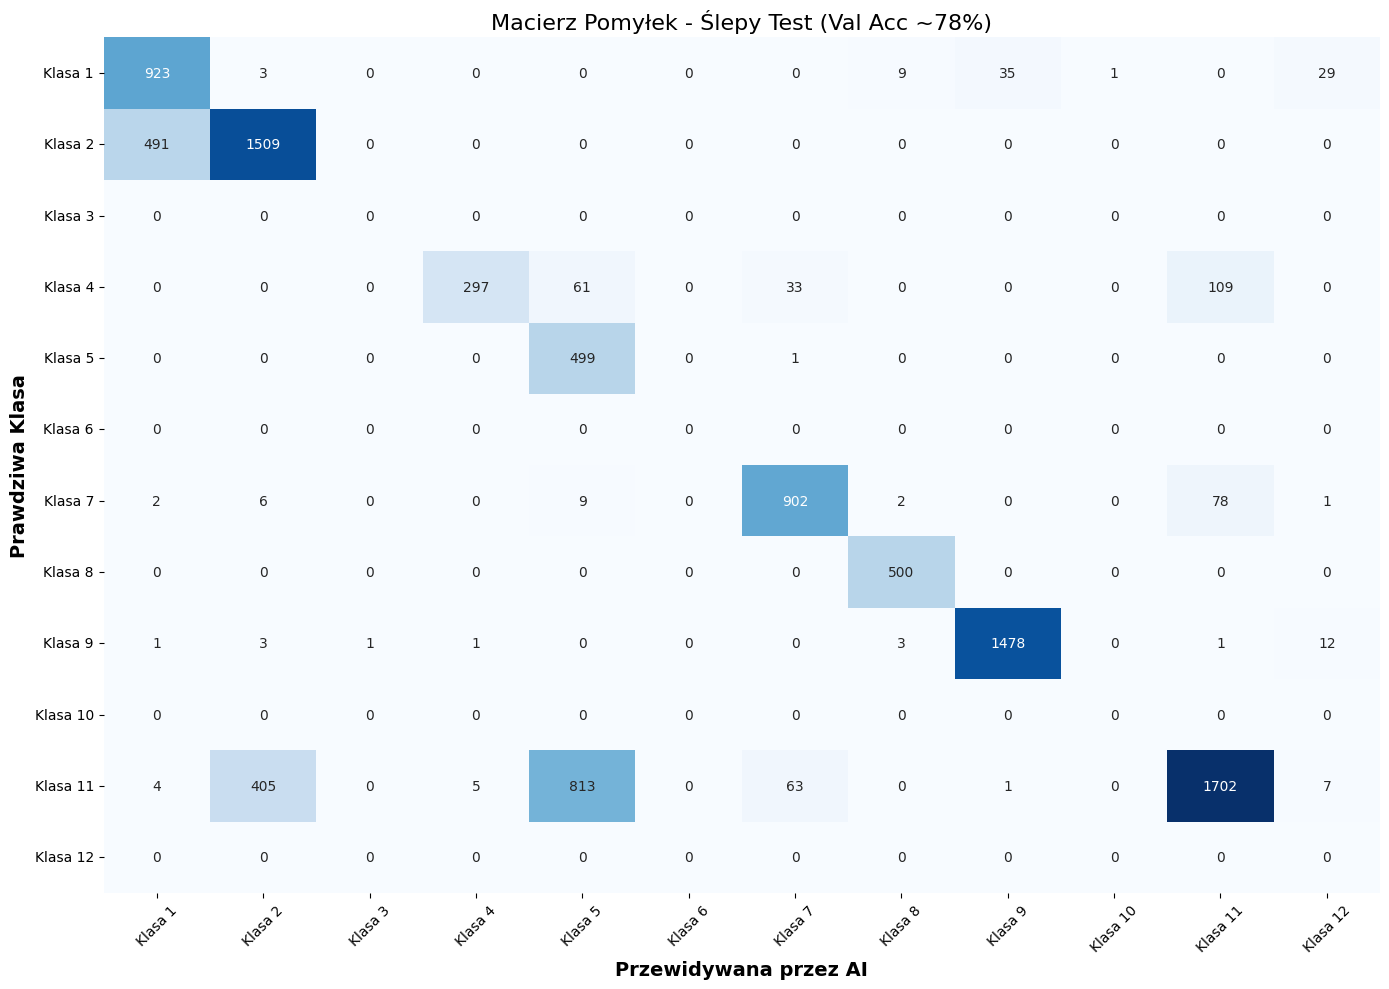

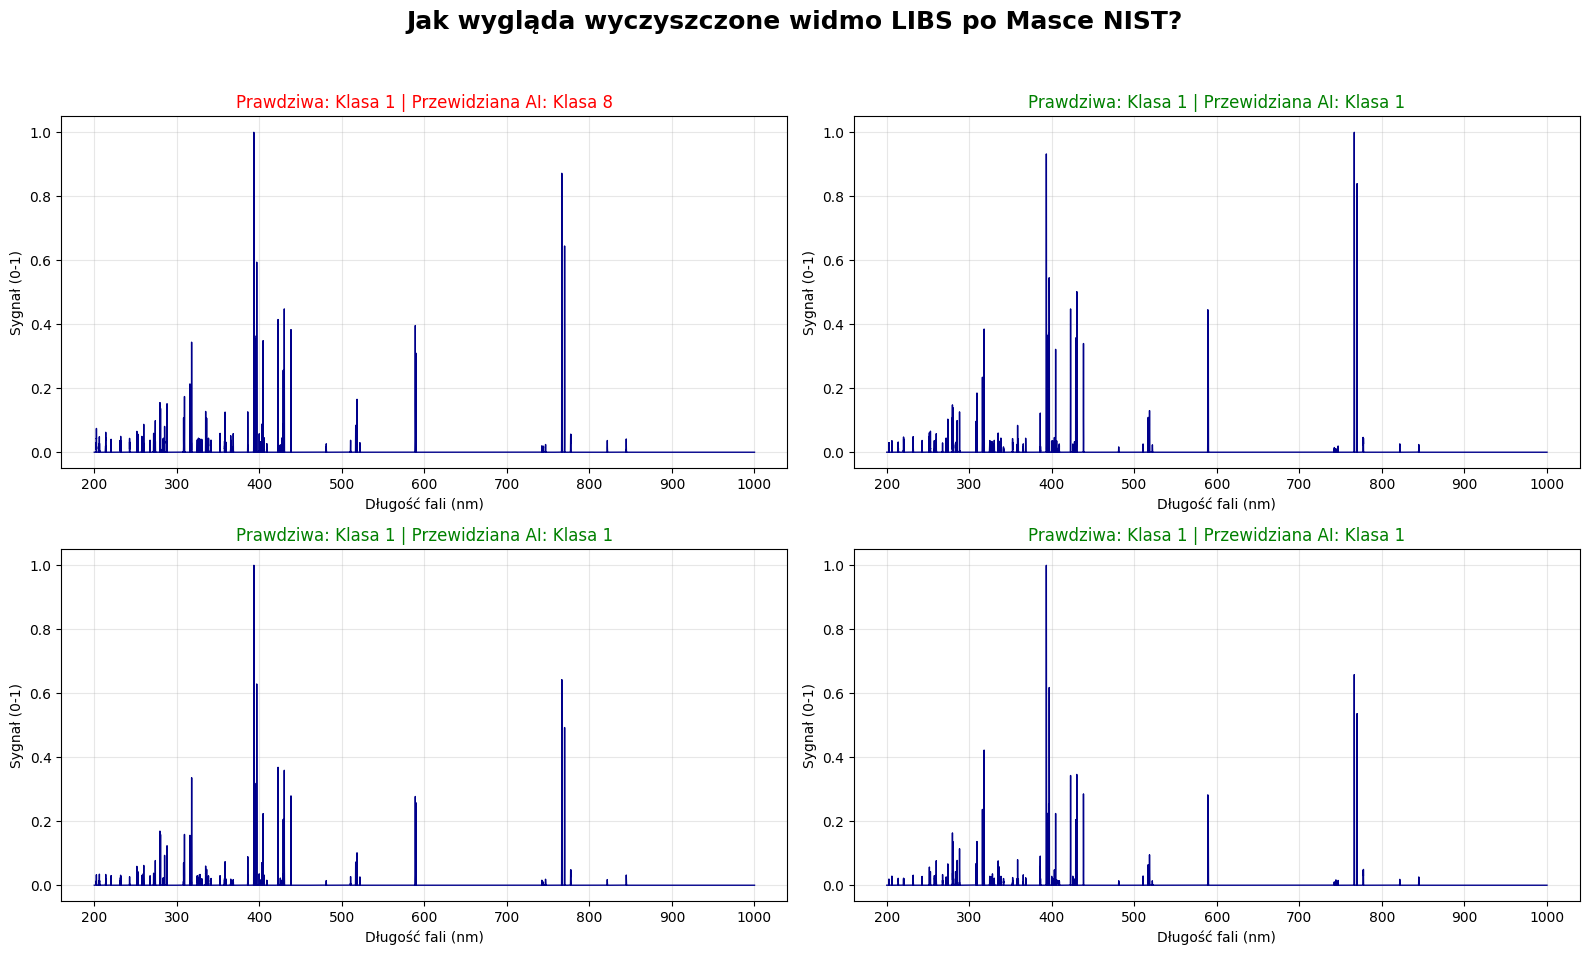

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Załadowanie NAJLEPSZYCH wag z 10. epoki (78.10%)
model.load_state_dict(torch.load('best_pian_resnet_2.pth', map_location=device))
model.eval()

all_preds = []
all_labels = []
sample_spectra = [] # Do wizualizacji fizycznej

print("Trwa ewaluacja NAJLEPSZEGO modelu na ślepym zbiorze testowym...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        # Pobieramy próbki do narysowania wykresów (z pierwszego batcha)
        if len(sample_spectra) < 4:
            for i in range(inputs.size(0)):
                if len(sample_spectra) < 4:
                    sample_spectra.append({
                        'spectrum': inputs[i].cpu().squeeze().numpy(),
                        'true_class': labels[i].item() + 1, # +1 dla klas 1-12
                        'pred_class': preds[i].item() + 1
                    })

# Konwersja na tablice numpy
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 2. RAPORT KLASYFIKACJI
print("\n" + "="*60)
print("SZCZEGÓŁOWY RAPORT KLASYFIKACJI (Na najlepszym modelu)")
print("="*60)
# Używamy etykiet 0-11, żeby uniknąć błędów w sklearn, a wyświetlamy Klasy 1-12
target_names = [f"Klasa {i+1}" for i in range(12)]
# labels=list(range(12)) upewnia się, że nawet jeśli brakuje jakiejś klasy w małym teście, kod nie wybuchnie
print(classification_report(all_labels, all_preds, target_names=target_names, labels=list(range(12)), zero_division=0))

# 3. MACIERZ POMYŁEK (Wizualizacja słabych punktów)
cm = confusion_matrix(all_labels, all_preds, labels=list(range(12)))

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Przewidywana przez AI', fontsize=14, fontweight='bold')
plt.ylabel('Prawdziwa Klasa', fontsize=14, fontweight='bold')
plt.title(f'Macierz Pomyłek - Ślepy Test (Val Acc ~78%)', fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. WIZUALIZACJA FIZYCZNA (Co widzi sieć?)
plt.figure(figsize=(16, 10))
plt.suptitle('Jak wygląda wyczyszczone widmo LIBS po Masce NIST?', fontsize=18, fontweight='bold')

for i, sample in enumerate(sample_spectra):
    plt.subplot(2, 2, i+1)
    
    # Rekonstrukcja osi nanometrów
    x_axis = np.linspace(200, 1000, 40002)
    
    plt.plot(x_axis, sample['spectrum'], color='darkblue', linewidth=1.0)
    
    color = 'green' if sample['true_class'] == sample['pred_class'] else 'red'
    plt.title(f"Prawdziwa: Klasa {sample['true_class']} | Przewidziana AI: Klasa {sample['pred_class']}", color=color)
    
    plt.xlabel("Długość fali (nm)")
    plt.ylabel("Sygnał (0-1)")
    plt.grid(True, alpha=0.3)
    plt.ylim(-0.05, 1.05) # Lepszy margines

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [13]:
import h5py
import numpy as np
import scipy.ndimage as ndimage
from tqdm import tqdm

# --- USTAWIENIA ---
INPUT_H5 = 'train.h5'                    
OUTPUT_H5_NO_MASK = 'train_cleaned_nomask.h5'      
WINDOW_SIZE = 100 

print(f"Tworzenie nowej bazy BEZ MASKI NIST: {OUTPUT_H5_NO_MASK}")
with h5py.File(INPUT_H5, 'r') as f_in, h5py.File(OUTPUT_H5_NO_MASK, 'w') as f_out:
    
    # Kopiujemy etykiety i długości fal
    f_out.create_dataset('Class/1', data=f_in['Class/1'][:], compression="gzip")
    if 'Wavelengths/1' in f_in:
        f_out.create_dataset('Wavelengths/1', data=f_in['Wavelengths/1'][:], compression="gzip")
    
    in_spectra_group = f_in['Spectra']
    out_spectra_group = f_out.create_group('Spectra')
    spectra_keys = list(in_spectra_group.keys())

    print("Rozpoczęcie odszumiania (bez maski fizycznej)...")
    for key in tqdm(spectra_keys, desc="Przetwarzanie bloków widm"):
        raw_matrix = in_spectra_group[key][:] 
        clean_matrix = np.zeros_like(raw_matrix)
        
        for idx in range(raw_matrix.shape[1]):
            spectrum = raw_matrix[:, idx]
            
            # Tylko usuwanie tła (Top-Hat) - zachowujemy wszystkie informacje!
            background = ndimage.minimum_filter(spectrum, size=WINDOW_SIZE)
            background = ndimage.maximum_filter(background, size=WINDOW_SIZE)
            flat_spectrum = spectrum - background
            flat_spectrum = np.clip(flat_spectrum, a_min=0.0, a_max=None)
            
            # Skalowanie Robust Min-Max
            spec_max = np.max(flat_spectrum)
            if spec_max > 0:
                flat_spectrum = flat_spectrum / spec_max
                
            clean_matrix[:, idx] = flat_spectrum
            
        out_spectra_group.create_dataset(key, data=clean_matrix, compression="gzip")

print("\n✅ PRE-PROCESSING BEZ MASKI ZAKOŃCZONY SUKCESEM!")

Tworzenie nowej bazy BEZ MASKI NIST: train_cleaned_nomask.h5
Rozpoczęcie odszumiania (bez maski fizycznej)...


Przetwarzanie bloków widm: 100%|██████████| 100/100 [08:52<00:00,  5.32s/it]



✅ PRE-PROCESSING BEZ MASKI ZAKOŃCZONY SUKCESEM!


In [14]:
import h5py
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler

# Klasa zmieniona, by czytać plik BEZ MASKI
class CleanedLIBSDataset_NoMask(Dataset):
    def __init__(self, h5_path='train_cleaned_nomask.h5'):
        self.h5_path = h5_path
        self.file = h5py.File(h5_path, 'r')
        self.labels = self.file['Class/1'][:]
        self.spectra_group = self.file['Spectra']
        self.keys = sorted(list(self.spectra_group.keys()))
        self.num_samples_per_key = 500
        self.total_samples = len(self.keys) * self.num_samples_per_key

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        key_idx = idx // self.num_samples_per_key
        shot_idx = idx % self.num_samples_per_key
        key = self.keys[key_idx]
        
        spectrum = self.spectra_group[key][:, shot_idx]
        
        # Wzmacniacz Słabych Sygnałów: Transformacja logarytmiczna
        # Podnosi ciche piki, spłaszcza wysokie
        spectrum = np.log1p(spectrum * 10) 
        
        label = int(self.labels[idx] - 1)
        return torch.tensor(spectrum, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

# 2. Przygotowanie danych z identycznym Group Split
full_dataset = CleanedLIBSDataset_NoMask()
all_keys = np.array(full_dataset.keys)
np.random.seed(42)
np.random.shuffle(all_keys)

split_idx = int(0.8 * len(all_keys))
train_keys = set(all_keys[:split_idx])
test_keys = set(all_keys[split_idx:])

train_indices = [i for i in range(len(full_dataset)) if full_dataset.keys[i // 500] in train_keys]
test_indices = [i for i in range(len(full_dataset)) if full_dataset.keys[i // 500] in test_keys]

train_dataset = Subset(full_dataset, train_indices)
test_dataset = Subset(full_dataset, test_indices)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, pin_memory=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, pin_memory=True, num_workers=0)

# 3. Model i Trening
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PIAN_ResNet(num_classes=12).to(device)

EPOCHS = 15
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
scheduler = lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=1)

print("\n--- ROZPOCZĘCIE TRENINGU: PEŁNE WIDMA + LOG TRANSFORM ---")
best_acc = 0.0

for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    train_acc = 100 * correct_train / total_train
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]
    
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    val_acc = 100 * correct_val / total_val
    time_taken = time.time() - start_time
    
    print(f"Epoka {epoch+1:02d}/{EPOCHS} [{time_taken:.1f}s] | LR: {current_lr:.5f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_resnet_nomask.pth')

print(f"\n✅ Trening zakończony! Najlepsze Validation Accuracy (Bez Maski): {best_acc:.2f}%")


--- ROZPOCZĘCIE TRENINGU: PEŁNE WIDMA + LOG TRANSFORM ---
Epoka 01/15 [1328.5s] | LR: 0.00090 | Train Acc: 79.27% | Val Acc: 75.01%
Epoka 02/15 [1312.3s] | LR: 0.00065 | Train Acc: 99.16% | Val Acc: 68.77%
Epoka 03/15 [1279.5s] | LR: 0.00035 | Train Acc: 99.77% | Val Acc: 84.45%
Epoka 04/15 [1291.1s] | LR: 0.00010 | Train Acc: 99.92% | Val Acc: 84.76%
Epoka 05/15 [1294.2s] | LR: 0.00100 | Train Acc: 99.98% | Val Acc: 78.06%
Epoka 06/15 [1299.2s] | LR: 0.00090 | Train Acc: 99.50% | Val Acc: 75.03%
Epoka 07/15 [1348.8s] | LR: 0.00065 | Train Acc: 99.82% | Val Acc: 70.82%
Epoka 08/15 [1317.6s] | LR: 0.00035 | Train Acc: 99.92% | Val Acc: 76.01%
Epoka 09/15 [1297.4s] | LR: 0.00010 | Train Acc: 99.99% | Val Acc: 81.09%
Epoka 10/15 [1317.1s] | LR: 0.00100 | Train Acc: 100.00% | Val Acc: 78.95%
Epoka 11/15 [1325.9s] | LR: 0.00090 | Train Acc: 99.66% | Val Acc: 84.55%
Epoka 12/15 [1408.5s] | LR: 0.00065 | Train Acc: 99.85% | Val Acc: 69.95%
Epoka 13/15 [1398.0s] | LR: 0.00035 | Train Acc: 99.

C:\Users\Ja\AppData\Local\Temp\ipykernel_25812\1144397269.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_resnet_nomask.pth', map_

Ewaluacja ostatecznego modelu (Bez Maski) na ślepym zbiorze testowym...

SZCZEGÓŁOWY RAPORT KLASYFIKACJI (Bez Maski NIST)
              precision    recall  f1-score   support

     Klasa 1       0.63      0.72      0.67      1000
     Klasa 2       0.94      0.79      0.86      2000
     Klasa 3       0.00      0.00      0.00         0
     Klasa 4       0.80      0.45      0.57       500
     Klasa 5       0.86      0.85      0.86       500
     Klasa 6       0.00      0.00      0.00         0
     Klasa 7       0.65      0.80      0.72      1000
     Klasa 8       0.90      1.00      0.95       500
     Klasa 9       0.88      1.00      0.94      1500
    Klasa 10       0.00      0.00      0.00         0
    Klasa 11       0.95      0.91      0.93      3000
    Klasa 12       0.00      0.00      0.00         0

    accuracy                           0.85     10000
   macro avg       0.55      0.54      0.54     10000
weighted avg       0.86      0.85      0.85     10000



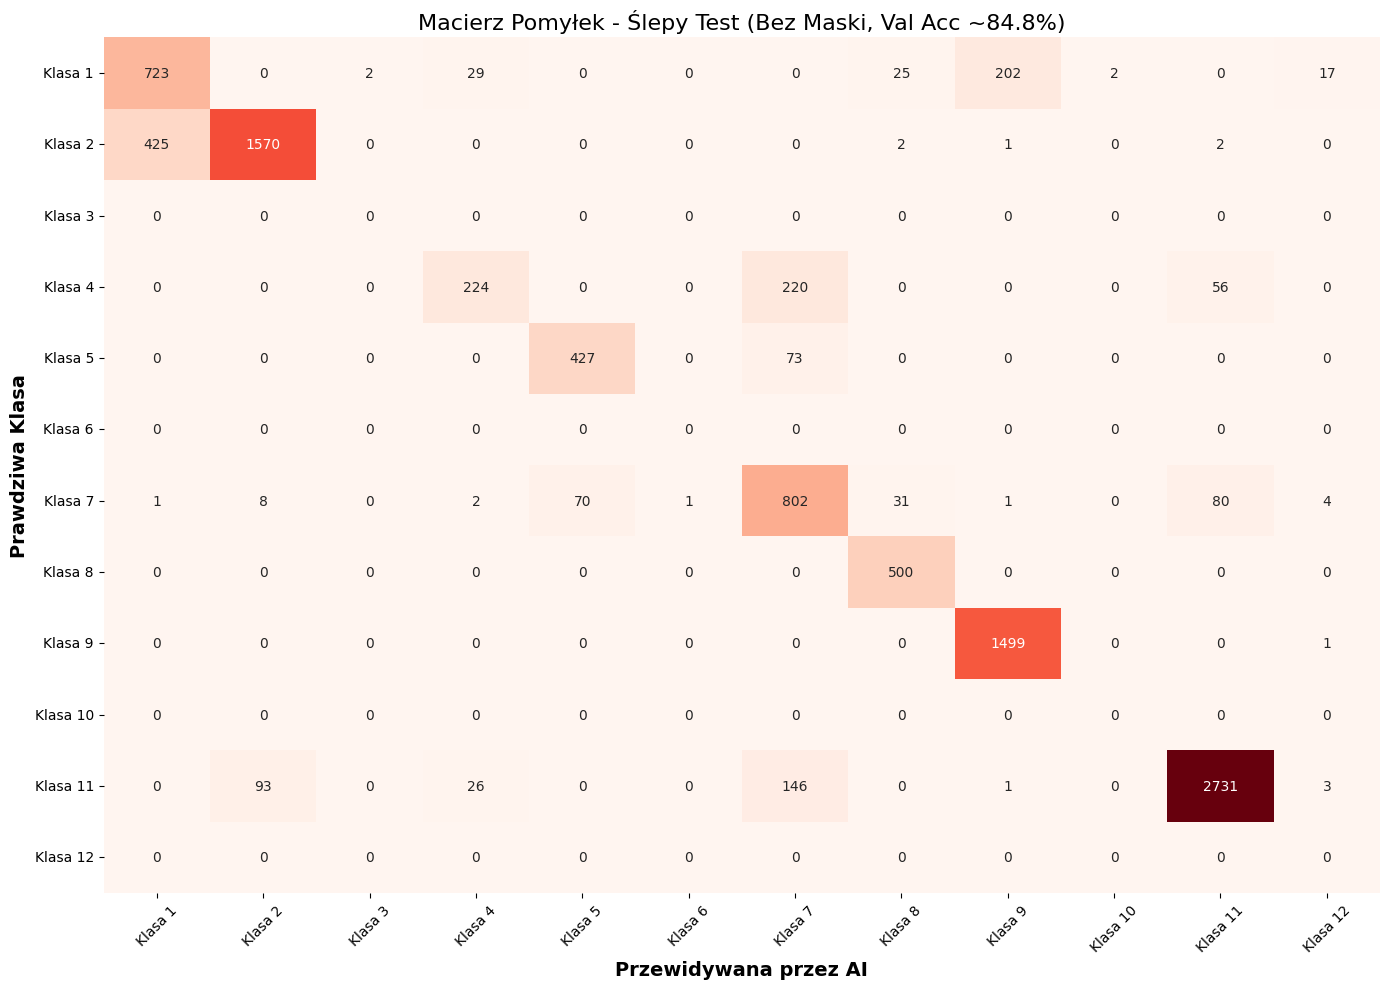

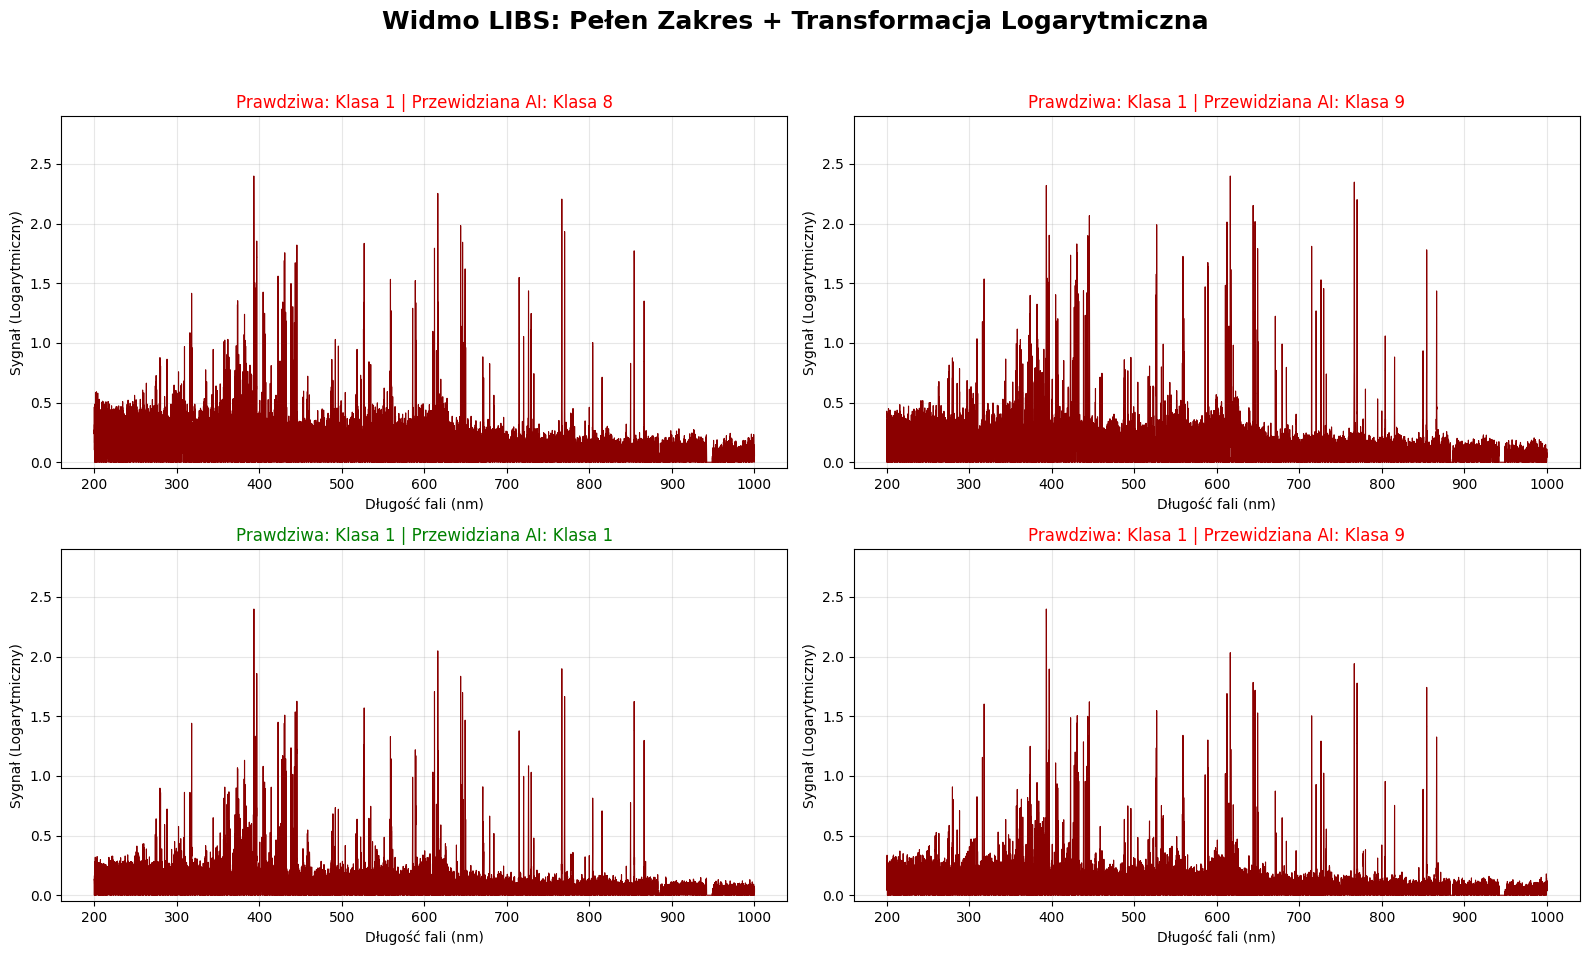

In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Załadowanie NAJLEPSZYCH wag modelu "Bez Maski" (z 4. epoki)
model.load_state_dict(torch.load('best_resnet_nomask.pth', map_location=device))
model.eval()

all_preds = []
all_labels = []
sample_spectra = [] 

print("Ewaluacja ostatecznego modelu (Bez Maski) na ślepym zbiorze testowym...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        if len(sample_spectra) < 4:
            for i in range(inputs.size(0)):
                if len(sample_spectra) < 4:
                    sample_spectra.append({
                        'spectrum': inputs[i].cpu().squeeze().numpy(),
                        'true_class': labels[i].item() + 1, 
                        'pred_class': preds[i].item() + 1
                    })

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 2. RAPORT KLASYFIKACJI
print("\n" + "="*60)
print("SZCZEGÓŁOWY RAPORT KLASYFIKACJI (Bez Maski NIST)")
print("="*60)
target_names = [f"Klasa {i+1}" for i in range(12)]
print(classification_report(all_labels, all_preds, target_names=target_names, labels=list(range(12)), zero_division=0))

# 3. MACIERZ POMYŁEK
cm = confusion_matrix(all_labels, all_preds, labels=list(range(12)))

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Przewidywana przez AI', fontsize=14, fontweight='bold')
plt.ylabel('Prawdziwa Klasa', fontsize=14, fontweight='bold')
plt.title(f'Macierz Pomyłek - Ślepy Test (Bez Maski, Val Acc ~84.8%)', fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. WIZUALIZACJA FIZYCZNA (Transformacja Logarytmiczna)
plt.figure(figsize=(16, 10))
plt.suptitle('Widmo LIBS: Pełen Zakres + Transformacja Logarytmiczna', fontsize=18, fontweight='bold')

for i, sample in enumerate(sample_spectra):
    plt.subplot(2, 2, i+1)
    x_axis = np.linspace(200, 1000, 40002)
    plt.plot(x_axis, sample['spectrum'], color='darkred', linewidth=0.8)
    
    color = 'green' if sample['true_class'] == sample['pred_class'] else 'red'
    plt.title(f"Prawdziwa: Klasa {sample['true_class']} | Przewidziana AI: Klasa {sample['pred_class']}", color=color)
    plt.xlabel("Długość fali (nm)")
    plt.ylabel("Sygnał (Logarytmiczny)")
    plt.grid(True, alpha=0.3)
    # Zwróć uwagę na spłaszczone wierzchołki i wyraźnie widoczne szumy u podstawy
    plt.ylim(-0.05, np.max(sample['spectrum']) + 0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Tutaj zorientowalem sie o strukturze danych, i ze na stronie byl tez plik test.h5 ;)
### Generalnie wszystkie wyniki powyzej tego markdowna sa do wyrzucenia ale nie chce ich usuwac

In [17]:
import h5py
import numpy as np
import scipy.ndimage as ndimage
from tqdm import tqdm

# --- USTAWIENIA DLA PLIKU TESTOWEGO ---
INPUT_TEST_H5 = 'test.h5'                    
OUTPUT_TEST_H5 = 'test_cleaned_nomask.h5'      
WINDOW_SIZE = 100 
BATCH_SIZE = 500 # Ochrona przed wybuchem pamięci RAM (ładujemy po 500 strzałów)

print(f"Tworzenie bazy testowej: {OUTPUT_TEST_H5}")
with h5py.File(INPUT_TEST_H5, 'r') as f_in, h5py.File(OUTPUT_TEST_H5, 'w') as f_out:
    
    if 'Wavelengths/1' in f_in:
        f_out.create_dataset('Wavelengths/1', data=f_in['Wavelengths/1'][:], compression="gzip")
    
    # Plik test.h5 trzyma dane w grupie 'UNKNOWN' zamiast 'Spectra'
    in_spectra_group = f_in['UNKNOWN']
    out_spectra_group = f_out.create_group('UNKNOWN')
    spectra_keys = list(in_spectra_group.keys()) # Będą to prawdopodobnie klucze '1' i '2'

    print("Rozpoczęcie odszumiania zbioru testowego (w trybie wsadowym/batch)...")
    for key in spectra_keys:
        raw_dataset = in_spectra_group[key]
        n_rows, n_cols = raw_dataset.shape # Wymiary, np. (40002, 10000)
        
        # Tworzymy pusty dataset w pliku docelowym. Typ float32 znacznie oszczędzi miejsce!
        out_dataset = out_spectra_group.create_dataset(
            key, shape=(n_rows, n_cols), dtype=np.float32, compression="gzip"
        )
        
        # Iterujemy przez kolumny (strzały) małymi paczkami
        for start_idx in tqdm(range(0, n_cols, BATCH_SIZE), desc=f"Przetwarzanie bloku UNKNOWN/{key}"):
            end_idx = min(start_idx + BATCH_SIZE, n_cols)
            
            # Wczytujemy z dysku do RAM tylko bezpieczny wycinek
            raw_batch = raw_dataset[:, start_idx:end_idx]
            clean_batch = np.zeros_like(raw_batch, dtype=np.float32)
            
            for idx in range(raw_batch.shape[1]):
                spectrum = raw_batch[:, idx]
                
                # Usuwanie tła (Top-Hat)
                background = ndimage.minimum_filter(spectrum, size=WINDOW_SIZE)
                background = ndimage.maximum_filter(background, size=WINDOW_SIZE)
                flat_spectrum = spectrum - background
                flat_spectrum = np.clip(flat_spectrum, a_min=0.0, a_max=None)
                
                # Skalowanie Robust Min-Max
                spec_max = np.max(flat_spectrum)
                if spec_max > 0:
                    flat_spectrum = flat_spectrum / spec_max
                    
                clean_batch[:, idx] = flat_spectrum
                
            # Zapisujemy wyczyszczoną paczkę na dysk i zwalniamy RAM
            out_dataset[:, start_idx:end_idx] = clean_batch

print("\n✅ PRE-PROCESSING DANYCH TESTOWYCH ZAKOŃCZONY SUKCESEM!")

Tworzenie bazy testowej: test_cleaned_nomask.h5
Rozpoczęcie odszumiania zbioru testowego (w trybie wsadowym/batch)...


Przetwarzanie bloku UNKNOWN/2: 100%|██████████| 20/20 [04:32<00:00, 13.65s/it]



✅ PRE-PROCESSING DANYCH TESTOWYCH ZAKOŃCZONY SUKCESEM!


Inicjalizacja Benchmark Datasetu...
Ładowanie etykiet testowych...


C:\Users\Ja\AppData\Local\Temp\ipykernel_25812\2791433715.py:70: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_resnet_nomask.pth', map


Rozpoczęcie ostatecznego testu na oficjalnym zbiorze konkursowym...


Ewaluacja Batchy: 100%|██████████| 157/157 [30:50<00:00, 11.79s/it]



OFICJALNY WYNIK BENCHMARKU - EMSLIBS19

🔥 OSTATECZNE ACCURACY: 67.52% 🔥

              precision    recall  f1-score   support

     Klasa 1       0.82      0.41      0.55      3146
     Klasa 2       1.00      0.97      0.99      3129
     Klasa 3       0.48      0.17      0.25       543
     Klasa 4       0.77      0.68      0.72      1603
     Klasa 5       0.26      0.56      0.35      1048
     Klasa 6       0.42      1.00      0.59      1589
     Klasa 7       0.43      0.17      0.24       560
     Klasa 8       0.75      1.00      0.86      1546
     Klasa 9       0.77      0.83      0.80      3127
    Klasa 10       0.53      0.96      0.68       514
    Klasa 11       1.00      0.33      0.50      3195
    Klasa 12       0.00      0.00      0.00         0

    accuracy                           0.68     20000
   macro avg       0.60      0.59      0.54     20000
weighted avg       0.77      0.68      0.67     20000



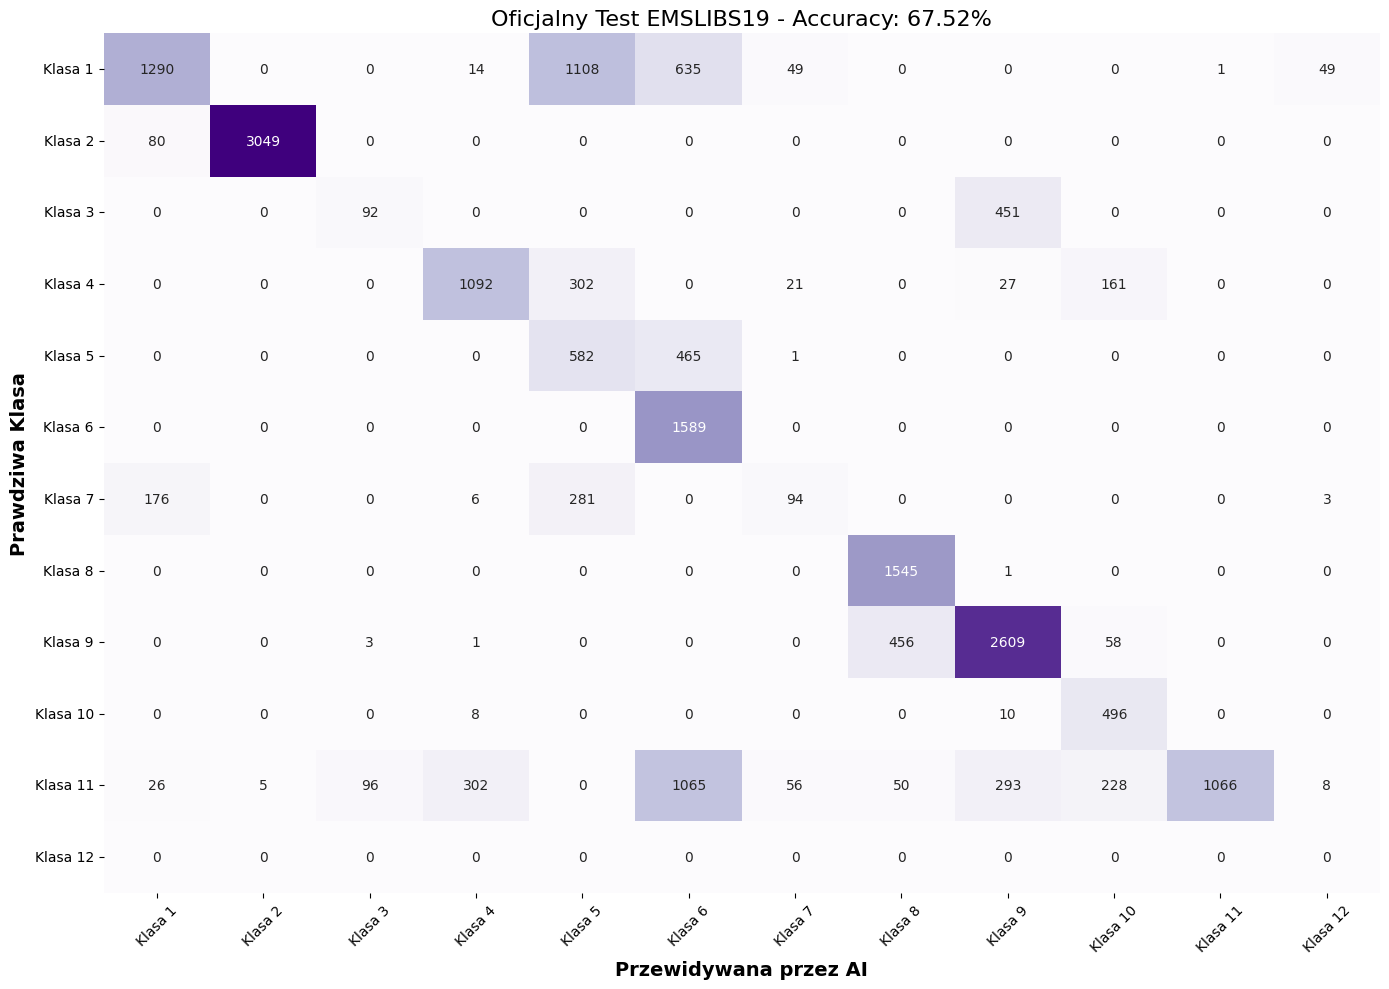

In [18]:
import h5py
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

# 1. Dedykowany DataLoader dla oficjalnego Testu
class OfficialBenchmarkTestDataset(Dataset):
    def __init__(self, h5_path='test_cleaned_nomask.h5', csv_path='test_labels.csv'):
        self.h5_path = h5_path
        
        # Wczytanie etykiet z CSV (brak nagłówka, pierwsza kolumna)
        print("Ładowanie etykiet testowych...")
        labels_df = pd.read_csv(csv_path, header=None)
        
        # Przesunięcie etykiet z 1-12 na 0-11 (wymóg PyTorcha)
        self.labels = labels_df[0].values - 1
        
        # Otwarcie pliku HDF5 i wczytanie kluczy
        self.file = h5py.File(h5_path, 'r')
        self.spectra_group = self.file['UNKNOWN']
        self.keys = sorted(list(self.spectra_group.keys())) # Prawdopodobnie '1' i '2'
        
        # Obliczanie fizycznego układu danych (gdzie kończy się '1', a zaczyna '2')
        self.key_boundaries = []
        current_idx = 0
        for key in self.keys:
            n_shots = self.spectra_group[key].shape[1]
            self.key_boundaries.append((current_idx, current_idx + n_shots, key))
            current_idx += n_shots
            
        self.total_samples = current_idx
        
        # Sprawdzenie spójności danych
        if self.total_samples != len(self.labels):
            print(f"OSTRZEŻENIE! Liczba widm ({self.total_samples}) nie zgadza się z liczbą etykiet ({len(self.labels)})!")

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        # Znalezienie odpowiedniego klucza i indeksu strzału na podstawie ogólnego indeksu
        for start, end, key in self.key_boundaries:
            if start <= idx < end:
                shot_idx = idx - start
                
                # Odczyt konkretnego strzału
                spectrum = self.spectra_group[key][:, shot_idx]
                
                # Transformacja logarytmiczna - MUSI BYĆ TAKA SAMA JAK W TRENINGU!
                spectrum = np.log1p(spectrum * 10)
                
                label = self.labels[idx]
                return torch.tensor(spectrum, dtype=torch.float32), torch.tensor(label, dtype=torch.long)
        
        raise IndexError("Indeks poza zasięgiem datasetu testowego.")

# 2. Inicjalizacja i załadowanie wag
print("Inicjalizacja Benchmark Datasetu...")
official_test_dataset = OfficialBenchmarkTestDataset()
official_test_loader = DataLoader(official_test_dataset, batch_size=128, shuffle=False, num_workers=0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Zakładam, że architektura PIAN_ResNet jest już załadowana w pamięci jupytera
model = PIAN_ResNet(num_classes=12).to(device)
model.load_state_dict(torch.load('best_resnet_nomask.pth', map_location=device))
model.eval()

# 3. Pętla Ewaluacyjna
all_preds = []
all_labels = []

print("\nRozpoczęcie ostatecznego testu na oficjalnym zbiorze konkursowym...")
with torch.no_grad():
    for inputs, labels in tqdm(official_test_loader, desc="Ewaluacja Batchy"):
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 4. Generowanie Raportu i Macierzy
print("\n" + "="*60)
print("OFICJALNY WYNIK BENCHMARKU - EMSLIBS19")
print("="*60)

# Obliczenie głównego Accuracy
accuracy = 100 * np.sum(all_preds == all_labels) / len(all_labels)
print(f"\n🔥 OSTATECZNE ACCURACY: {accuracy:.2f}% 🔥\n")

target_names = [f"Klasa {i+1}" for i in range(12)]
print(classification_report(all_labels, all_preds, target_names=target_names, labels=list(range(12)), zero_division=0))

cm = confusion_matrix(all_labels, all_preds, labels=list(range(12)))

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Przewidywana przez AI', fontsize=14, fontweight='bold')
plt.ylabel('Prawdziwa Klasa', fontsize=14, fontweight='bold')
plt.title(f'Oficjalny Test EMSLIBS19 - Accuracy: {accuracy:.2f}%', fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Next attempt + new dataloaders


In [7]:
import h5py
import numpy as np
from tqdm import tqdm

def convert_h5_to_memmap():
    print("Konwersja Train HDF5 -> Memmap (Szybki odczyt)...")
    with h5py.File('train_cleaned_nomask.h5', 'r') as f:
        keys = sorted(list(f['Spectra'].keys()))
        num_samples = len(keys) * 500
        
        # Tworzymy surowy plik na dysku SSD (tryb w+)
        fp = np.memmap('train_spectra_fast.npy', dtype='float32', mode='w+', shape=(num_samples, 40002))
        labels = np.zeros(num_samples, dtype='int64')
        
        idx = 0
        for k in tqdm(keys, desc="Zrzucanie do pliku binarnego"):
            # Odczytujemy blok i OBRACAMY GO (.T), aby próbki były zapisane jedna po drugiej
            block = f['Spectra'][k][:].T 
            fp[idx:idx+500, :] = block
            labels[idx:idx+500] = f['Class/1'][idx:idx+500] - 1
            idx += 500
            
        fp.flush() # Wymuszenie zapisu na dysk
        np.save('train_labels_fast.npy', labels)
        print("✅ Zakończono konwersję treningu!")

# Odpal tę funkcję raz
convert_h5_to_memmap()

Konwersja Train HDF5 -> Memmap (Szybki odczyt)...


Zrzucanie do pliku binarnego:   0%|          | 0/100 [00:00<?, ?it/s]

Zrzucanie do pliku binarnego: 100%|██████████| 100/100 [03:22<00:00,  2.02s/it]


✅ Zakończono konwersję treningu!


In [4]:
import h5py
import pandas as pd
import numpy as np
from tqdm import tqdm

def convert_test_to_memmap():
    print("Konwersja Test HDF5 -> Memmap (Błyskawiczny odczyt dla GPU)...")
    
    # Wczytujemy etykiety testowe
    labels_df = pd.read_csv('test_labels.csv', header=None)
    labels = labels_df[0].values - 1
    
    with h5py.File('test_cleaned_nomask.h5', 'r') as f:
        keys = sorted(list(f['UNKNOWN'].keys()))
        
        # Obliczamy całkowitą liczbę strzałów w teście
        total_samples = sum(f['UNKNOWN'][k].shape[1] for k in keys)
        print(f"Znaleziono {total_samples} widm testowych.")
        
        # Tworzymy surowy plik memmap
        fp = np.memmap('test_spectra_fast.npy', dtype='float32', mode='w+', shape=(total_samples, 40002))
        
        idx = 0
        for k in tqdm(keys, desc="Zrzucanie Testu do pliku binarnego"):
            n_shots = f['UNKNOWN'][k].shape[1]
            block = f['UNKNOWN'][k][:].T 
            fp[idx:idx+n_shots, :] = block
            idx += n_shots
            
        fp.flush()
        np.save('test_labels_fast.npy', labels)
        print("✅ Zakończono konwersję testu! Możesz usunąć tę komórkę.")

convert_test_to_memmap()

Konwersja Test HDF5 -> Memmap (Błyskawiczny odczyt dla GPU)...
Znaleziono 20000 widm testowych.


Zrzucanie Testu do pliku binarnego: 100%|██████████| 2/2 [00:28<00:00, 14.38s/it]


✅ Zakończono konwersję testu! Możesz usunąć tę komórkę.


In [6]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset

import torch
import torch.nn as nn

# 1. Moduł Squeeze-and-Excitation (Mechanizm Uwagi)
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1) # Squeeze
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid() # Excitation (wagi od 0 do 1)
        )

    def forward(self, x):
        b, c, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y.expand_as(x) # Wzmacnianie i wyciszanie filtrów

# 2. Blok ResNet z Uwagą
class ResNetBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=7, stride=stride, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=7, stride=1, padding=3, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels) # Nasz moduł uwagi

        self.downsample = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out)     # Aplikujemy Uwagę
        out += identity        # Autostrada resztkowa (Skip Connection)
        out = self.relu(out)
        return out

# 3. Główna Sieć (PIAN)
class PIAN_ResNet(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        # Zjadamy te 40 002 punkty ogromnym krokiem (stride=4), żeby ulżyć procesorowi
        self.conv1 = nn.Conv1d(1, 32, kernel_size=15, stride=4, padding=7, bias=False)
        self.bn1 = nn.BatchNorm1d(32)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=4, stride=4) # Zostało ~2500 punktów

        # Gęsty las głębokich konwolucji
        self.layer1 = ResNetBlock1D(32, 64, stride=2)   # ~1250 punktów
        self.layer2 = ResNetBlock1D(64, 128, stride=2)  # ~625 punktów
        self.layer3 = ResNetBlock1D(128, 256, stride=2) # ~312 punktów

        # Nowoczesne przejście do klasyfikatora
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# --- 1. SZYBKIE DATASETY MEMMAP ---
class Memmap_TrainDataset(Dataset):
    def __init__(self, data_path='train_spectra_fast.npy', labels_path='train_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        # Ochrona przed memory-leakami PyTorcha
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

class Memmap_TestDataset(Dataset):
    def __init__(self, data_path='test_spectra_fast.npy', labels_path='test_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

# --- 2. SILNIK MIXUP ---
def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [6]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm

if __name__ == '__main__':
    print("\nInicjalizacja superszybkich DataLoaderów Memmap...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    # Z powodu problemów z wielowątkowością na Windowsie (deadlocki), 
    # używamy num_workers=0. Ponieważ zrzuciliśmy dane do memmap, i tak będzie błyskawicznie!
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nModel trenowany na urządzeniu: {device}")
    
    # Inicjalizacja Twojego modelu (zastąp jeśli Twoja klasa nazywa się inaczej)
    model = PIAN_ResNet(num_classes=12).to(device) 

    EPOCHS = 20
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    scheduler = lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=1)
    
    # Skaler do mieszanej precyzji - klucz do wydajności kart RTX
    scaler = torch.amp.GradScaler('cuda')

    print("\n--- ROZPOCZĘCIE TRENINGU SotA: GPU AUGMENTACJA + MIXUP ---")
    best_acc = 0.0

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        # Pętla Treningowa
        pbar_train = tqdm(train_loader, desc=f"Epoka {epoch+1:02d}/{EPOCHS} [Trening]")
        for inputs, labels in pbar_train:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            optimizer.zero_grad(set_to_none=True)
            
            # Autocast i obliczenia wektorowe zrzucone w całości na kartę graficzną
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    inputs = torch.log1p(inputs * 10.0)
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise
                
                inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.2)
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            pbar_train.set_postfix({'Loss': f"{running_loss/len(train_loader):.4f}"})
            
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]
        
        # Pętla Testowa (Ewaluacja)
        model.eval()
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            pbar_test = tqdm(test_loader, desc=f"Epoka {epoch+1:02d}/{EPOCHS} [Test]", leave=False)
            for inputs, labels in pbar_test:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                
                with torch.amp.autocast('cuda'):
                    # Zbiór testowy wymaga LOGARYTMU, ale NIE szumu/skalowania!
                    inputs = torch.log1p(inputs * 10.0)
                    outputs = model(inputs)
                    
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        val_acc = 100 * correct_val / total_val
        time_taken = time.time() - start_time
        
        print(f"✅ Epoka {epoch+1:02d}/{EPOCHS} zakończona w {time_taken:.1f}s | LR: {current_lr:.5f} | Wynik Testu: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_sota.pth')
            print(f"   🔥 Nowy rekord zapisany! ({best_acc:.2f}%)")

    print(f"\n🏆 Trening zakończony! Najlepszy Wynik Benchmarku: {best_acc:.2f}%")


Inicjalizacja superszybkich DataLoaderów Memmap...

Model trenowany na urządzeniu: cuda

--- ROZPOCZĘCIE TRENINGU SotA: GPU AUGMENTACJA + MIXUP ---


Epoka 01/20 [Trening]: 100%|██████████| 196/196 [01:02<00:00,  3.14it/s, Loss=1.5781]


✅ Epoka 01/20 zakończona w 82.8s | LR: 0.00090 | Wynik Testu: 42.17%
   🔥 Nowy rekord zapisany! (42.17%)


Epoka 02/20 [Trening]: 100%|██████████| 196/196 [01:25<00:00,  2.30it/s, Loss=0.9994]


✅ Epoka 02/20 zakończona w 110.8s | LR: 0.00065 | Wynik Testu: 42.45%
   🔥 Nowy rekord zapisany! (42.45%)


...

✅ Epoka 18/20 zakończona w 65.7s | LR: 0.00035 | Wynik Testu: 69.46%


Epoka 19/20 [Trening]: 100%|██████████| 196/196 [00:40<00:00,  4.90it/s, Loss=0.8171]


✅ Epoka 19/20 zakończona w 61.8s | LR: 0.00010 | Wynik Testu: 68.90%


Epoka 20/20 [Trening]: 100%|██████████| 196/196 [00:47<00:00,  4.15it/s, Loss=0.8004]


✅ Epoka 20/20 zakończona w 62.7s | LR: 0.00100 | Wynik Testu: 66.77%

🏆 Trening zakończony! Najlepszy Wynik Benchmarku: 70.60%


In [5]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset

# --- 1. SZYBKIE DATASETY MEMMAP ---
# Traktują dysk SSD jak RAM, całkowicie eliminując wąskie gardło CPU/HDF5
class Memmap_TrainDataset(Dataset):
    def __init__(self, data_path='train_spectra_fast.npy', labels_path='train_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx]) # Kopia zapobiega wyciekom pamięci w PyTorchu
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

class Memmap_TestDataset(Dataset):
    def __init__(self, data_path='test_spectra_fast.npy', labels_path='test_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

# --- 2. SILNIK MIXUP ---
# Zmusza model do niesamowitej generalizacji poprzez miksowanie widm w locie
def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [8]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm

if __name__ == '__main__':
    print("\n[1/3] Inicjalizacja superszybkich DataLoaderów Memmap...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    # Omijamy deadlocki Windowsa ustawiając num_workers=0. Odczyt .npy i tak jest błyskawiczny.
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[2/3] Model trenowany na urządzeniu: {device} (Mieszana Precyzja Aktywna)")
    
    model = PIAN_ResNet(num_classes=12).to(device) 

    # === USTAWIENIA NOCNEGO MARATONU ===
    EPOCHS = 300 
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
    
    # Delikatniejszy weight_decay (0.005), aby sieć łatwiej łapała mikroskopijne cechy widma
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
    
    # Jeden długi, majestatyczny spadek LR. Zaczyna od 0.001, kończy blisko zera w 300. epoce.
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    
    # Skaler chroniący przed underflow gradientów przy mieszanej precyzji (fp16)
    scaler = torch.amp.GradScaler('cuda')

    print(f"\n[3/3] --- ROZPOCZĘCIE NOCNEGO MARATONU ({EPOCHS} EPOK) O REKORD EMSLIBS19 ---")
    best_acc = 0.0

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        # Pętla Treningowa
        pbar_train = tqdm(train_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Trening]")
        for inputs, labels in pbar_train:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            optimizer.zero_grad(set_to_none=True)
            
            # Autocast - zrzucamy ciężką matematykę na Tensor Cores w RTX 3080 Ti
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    inputs = torch.log1p(inputs * 10.0)
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise
                
                inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.2)
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            pbar_train.set_postfix({'Loss': f"{running_loss/len(train_loader):.4f}"})
            
        # Aktualizacja harmonogramu PO KAŻDEJ EPOCE
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]
        
        # Pętla Testowa (Ewaluacja bez szumu/skalowania)
        model.eval()
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            pbar_test = tqdm(test_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Test]", leave=False)
            for inputs, labels in pbar_test:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                
                with torch.amp.autocast('cuda'):
                    inputs = torch.log1p(inputs * 10.0) # Tu ZAWSZE musi być logarytm!
                    outputs = model(inputs)
                    
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        val_acc = 100 * correct_val / total_val
        time_taken = time.time() - start_time
        
        print(f"✅ Epoka {epoch+1:03d}/{EPOCHS} zakończona w {time_taken:.1f}s | LR: {current_lr:.6f} | Wynik Testu: {val_acc:.2f}%")
        
        # Zapisujemy najlepsze wagi
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_sota_long.pth')
            print(f"   🔥 Nowy rekord nocny zapisany! ({best_acc:.2f}%)")

    print(f"\n🏆 MARATON ZAKOŃCZONY! Twój najlepszy wynik to: {best_acc:.2f}%")


[1/3] Inicjalizacja superszybkich DataLoaderów Memmap...
[2/3] Model trenowany na urządzeniu: cuda (Mieszana Precyzja Aktywna)

[3/3] --- ROZPOCZĘCIE NOCNEGO MARATONU (300 EPOK) O REKORD EMSLIBS19 ---


Epoka 001/300 [Trening]: 100%|██████████| 196/196 [00:59<00:00,  3.31it/s, Loss=1.5781]


✅ Epoka 001/300 zakończona w 98.0s | LR: 0.001000 | Wynik Testu: 45.37%
   🔥 Nowy rekord nocny zapisany! (45.37%)


Epoka 002/300 [Trening]: 100%|██████████| 196/196 [00:59<00:00,  3.32it/s, Loss=0.9731]


✅ Epoka 002/300 zakończona w 85.7s | LR: 0.001000 | Wynik Testu: 62.56%
   🔥 Nowy rekord nocny zapisany! (62.56%)


...

✅ Epoka 298/300 zakończona w 30.2s | LR: 0.000001 | Wynik Testu: 73.09%


Epoka 299/300 [Trening]: 100%|██████████| 196/196 [00:28<00:00,  6.81it/s, Loss=0.7469]


✅ Epoka 299/300 zakończona w 33.8s | LR: 0.000001 | Wynik Testu: 73.31%


Epoka 300/300 [Trening]: 100%|██████████| 196/196 [00:22<00:00,  8.78it/s, Loss=0.7550]
                                                                     

✅ Epoka 300/300 zakończona w 24.7s | LR: 0.000001 | Wynik Testu: 73.25%

🏆 MARATON ZAKOŃCZONY! Twój najlepszy wynik to: 76.52%


In [5]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm import tqdm

print("--- OSTATECZNA EWALUACJA Z TTA (Test-Time Augmentation) ---")

# 1. Inicjalizacja i wczytanie 'złotych wag' z 84. epoki
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PIAN_ResNet(num_classes=12).to(device)
model.load_state_dict(torch.load('best_resnet_sota_long.pth', map_location=device, weights_only=True))
model.eval() # Tryb ewaluacji

test_dataset = Memmap_TestDataset()
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, pin_memory=True, num_workers=0)

correct_tta = 0
total = 0

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Ewaluacja TTA"):
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        
        # Baza: logarytmizacja
        inputs_log = torch.log1p(inputs * 10.0)
        
        # TTA 1: Surowe dane (tylko logarytm)
        logits_1 = model(inputs_log)
        
        # TTA 2: Symulacja wzrostu mocy lasera o 10%
        logits_2 = model(torch.log1p((inputs * 1.10) * 10.0))
        
        # TTA 3: Symulacja spadku mocy lasera o 10%
        logits_3 = model(torch.log1p((inputs * 0.90) * 10.0))
        
        # TTA 4: Bardzo delikatny szum matrycy
        noise = torch.randn_like(inputs) * 0.02 * torch.max(inputs, dim=1, keepdim=True).values
        logits_4 = model(torch.log1p(torch.clamp(inputs + noise, min=0.0) * 10.0))
        
        # Uśrednianie prawdopodobieństw (Softmax), a nie surowych logitów
        probs_1 = F.softmax(logits_1, dim=1)
        probs_2 = F.softmax(logits_2, dim=1)
        probs_3 = F.softmax(logits_3, dim=1)
        probs_4 = F.softmax(logits_4, dim=1)
        
        # "Głosowanie Zespołowe" jednego modelu
        avg_probs = (probs_1 + probs_2 + probs_3 + probs_4) / 4.0
        
        _, predicted = torch.max(avg_probs, 1)
        total += labels.size(0)
        correct_tta += (predicted == labels).sum().item()

final_accuracy = 100 * correct_tta / total
print(f"\n🏆 OSTATECZNY WYNIK EMSLIBS19 PO TTA: {final_accuracy:.2f}%")

--- OSTATECZNA EWALUACJA Z TTA (Test-Time Augmentation) ---


Ewaluacja TTA: 100%|██████████| 79/79 [00:08<00:00,  9.39it/s]


🏆 OSTATECZNY WYNIK EMSLIBS19 PO TTA: 76.25%


In [2]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm

if __name__ == '__main__':
    print("\n[1/3] Inicjalizacja superszybkich DataLoaderów Memmap...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    # Omijamy deadlocki Windowsa ustawiając num_workers=0. Odczyt .npy i tak jest błyskawiczny.
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[2/3] Model trenowany na urządzeniu: {device} (Mieszana Precyzja Aktywna)")
    
    # Inicjalizacja Twojego modelu
    model = PIAN_ResNet(num_classes=12).to(device) 

    # === USTAWIENIA MARATONU O REKORD (300 EPOK) ===
    EPOCHS = 300 
    
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
    
    # Majestatyczny spadek LR przez 300 epok, idealny dla nocnych treningów
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    
    # Skaler chroniący przed podmiarem (underflow) przy FP16
    scaler = torch.amp.GradScaler('cuda')

    print(f"\n[3/3] --- ROZPOCZĘCIE MARATONU ({EPOCHS} EPOK) Z UŻYCIEM SPECAUGMENT ---")
    best_acc = 0.0

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        # Pętla Treningowa
        pbar_train = tqdm(train_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Trening]")
        for inputs, labels in pbar_train:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            optimizer.zero_grad(set_to_none=True)
            
            # Autocast - Mieszana precyzja na RTX 3080 Ti
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    # 1. Baza: Logarytm
                    inputs = torch.log1p(inputs * 10.0)
                    
                    # 2. Skalowanie mocy lasera
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    
                    # 3. Szum matrycy
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise
                    
                    # ==========================================
                    # 4. SPECAUGMENT (Brutalne Oślepianie Sieci)
                    # ==========================================
                    batch_size = inputs.size(0)
                    seq_len = inputs.size(1) # Zazwyczaj 40002
                    
                    # Losowa szerokość "dziury" od 100 do 2000 pikseli
                    mask_width = torch.randint(100, 2000, (batch_size, 1), device=device)
                    # Losowy punkt startowy "dziury"
                    start_idx = (torch.rand(batch_size, 1, device=device) * (seq_len - mask_width)).long()
                    
                    # Generowanie maski logicznej dla całego batcha
                    indices = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, -1)
                    mask = (indices >= start_idx) & (indices < start_idx + mask_width)
                    
                    # Zastępowanie wyciętych pikseli średnią wartością z danego widma
                    mean_vals = inputs.mean(dim=1, keepdim=True) 
                    inputs = torch.where(mask, mean_vals, inputs)
                    # ==========================================
                
                # 5. MixUp (miksowanie próbek z nałożonym już SpecAugmentem!)
                inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.2)
                
                # Propagacja w przód i obliczenie błędu
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            
            # Wsteczna propagacja gradientu ze skalerem
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            pbar_train.set_postfix({'Loss': f"{running_loss/len(train_loader):.4f}"})
            
        # Krok Schedulera co epokę
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]
        
        # === PĘTLA TESTOWA (Ewaluacja) ===
        model.eval()
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            pbar_test = tqdm(test_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Test]", leave=False)
            for inputs, labels in pbar_test:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                
                with torch.amp.autocast('cuda'):
                    # Zbiór testowy MA ZAWSZE LOGARYTM, ale zero szumów, cięć czy skalowania
                    inputs = torch.log1p(inputs * 10.0)
                    outputs = model(inputs)
                    
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        val_acc = 100 * correct_val / total_val
        time_taken = time.time() - start_time
        
        print(f"✅ Epoka {epoch+1:03d}/{EPOCHS} [{time_taken:.1f}s] | LR: {current_lr:.6f} | Wynik Testu: {val_acc:.2f}%")
        
        # Zapis najlepszych wag
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_sota.pth')
            print(f"   🔥 Nowy rekord zapisany! ({best_acc:.2f}%)")

    print(f"\n🏆 TRENING ZAKOŃCZONY! Twój ostateczny najlepszy wynik to: {best_acc:.2f}%")


[1/3] Inicjalizacja superszybkich DataLoaderów Memmap...
[2/3] Model trenowany na urządzeniu: cuda (Mieszana Precyzja Aktywna)

[3/3] --- ROZPOCZĘCIE MARATONU (300 EPOK) Z UŻYCIEM SPECAUGMENT ---


Epoka 001/300 [Trening]: 100%|██████████| 196/196 [01:46<00:00,  1.84it/s, Loss=1.5042]


✅ Epoka 001/300 [126.1s] | LR: 0.001000 | Wynik Testu: 59.49%
   🔥 Nowy rekord zapisany! (59.49%)


Epoka 002/300 [Trening]: 100%|██████████| 196/196 [01:31<00:00,  2.14it/s, Loss=0.9627]


✅ Epoka 002/300 [127.2s] | LR: 0.001000 | Wynik Testu: 65.11%
   🔥 Nowy rekord zapisany! (65.11%)


...

✅ Epoka 298/300 [15.0s] | LR: 0.000001 | Wynik Testu: 54.10%


Epoka 299/300 [Trening]: 100%|██████████| 196/196 [00:12<00:00, 15.65it/s, Loss=0.7374]


✅ Epoka 299/300 [14.9s] | LR: 0.000001 | Wynik Testu: 52.59%


Epoka 300/300 [Trening]: 100%|██████████| 196/196 [00:12<00:00, 15.69it/s, Loss=0.7665]
                                                                     

✅ Epoka 300/300 [14.8s] | LR: 0.000001 | Wynik Testu: 58.47%

🏆 TRENING ZAKOŃCZONY! Twój ostateczny najlepszy wynik to: 75.15%


In [3]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm import tqdm
import random
import numpy as np
import os

# --- FUNKCJA ZAMRAŻAJĄCA LOSOWOŚĆ (Klucz do Ensemblingu) ---
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if __name__ == '__main__':
    print("\n[1/4] Inicjalizacja superszybkich DataLoaderów Memmap...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[2/4] Architektura gotowa. Karta: {device}")

    # Lista ziaren (Trzech niezależnych ekspertów)
    SEEDS = [42, 777, 2024]
    EPOCHS = 100 # 100 epok w zupełności wystarczy dla jednego modelu
    
    saved_models = []

    print("\n[3/4] --- ROZPOCZĘCIE TRENINGU ZESPOŁOWEGO (3 MODELE) ---")
    
    # === PĘTLA ENSEMBLINGU ===
    for model_idx, seed in enumerate(SEEDS):
        print(f"\n" + "="*50)
        print(f"🚀 TRENOWANIE EKSPERTA {model_idx+1}/{len(SEEDS)} (Seed: {seed})")
        print("="*50)
        
        seed_everything(seed)
        
        # Nowa, czysta inicjalizacja modelu dla każdego ziarna!
        model = PIAN_ResNet(num_classes=12).to(device) 
        
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
        optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
        scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        scaler = torch.amp.GradScaler('cuda')

        best_acc = 0.0
        best_model_name = f'best_resnet_seed_{seed}.pth'

        for epoch in range(EPOCHS):
            model.train()
            running_loss = 0.0
            
            pbar_train = tqdm(train_loader, desc=f"M{model_idx+1} Epoka {epoch+1:03d}/{EPOCHS} [Trening]", leave=False)
            for inputs, labels in pbar_train:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                
                with torch.amp.autocast('cuda'):
                    with torch.no_grad():
                        inputs = torch.log1p(inputs * 10.0)
                        scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                        inputs = inputs * scale
                        noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                        inputs = inputs + noise
                        
                        # SpecAugment
                        batch_size, seq_len = inputs.shape
                        mask_width = torch.randint(100, 2000, (batch_size, 1), device=device)
                        start_idx = (torch.rand(batch_size, 1, device=device) * (seq_len - mask_width)).long()
                        indices = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, -1)
                        mask = (indices >= start_idx) & (indices < start_idx + mask_width)
                        mean_vals = inputs.mean(dim=1, keepdim=True) 
                        inputs = torch.where(mask, mean_vals, inputs)
                    
                    inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.2)
                    outputs = model(inputs)
                    loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
                
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
                scaler.step(optimizer)
                scaler.update()
                
                running_loss += loss.item()
                
            scheduler.step()
            
            # Szybka Ewaluacja w trakcie treningu (tylko baza)
            model.eval()
            correct_val, total_val = 0, 0
            with torch.no_grad():
                for inputs, labels in test_loader:
                    inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                    with torch.amp.autocast('cuda'):
                        outputs = model(torch.log1p(inputs * 10.0))
                    _, predicted = torch.max(outputs.data, 1)
                    total_val += labels.size(0)
                    correct_val += (predicted == labels).sum().item()
                    
            val_acc = 100 * correct_val / total_val
            
            if val_acc > best_acc:
                best_acc = val_acc
                torch.save(model.state_dict(), best_model_name)
                
        print(f"✅ Ekspert {model_idx+1} wytrenowany. Najlepszy pojedynczy wynik: {best_acc:.2f}%")
        saved_models.append(best_model_name)

    # ====================================================================
    # [4/4] OSTATECZNE GŁOSOWANIE ZESPOŁOWE (ENSEMBLE + TTA)
    # ====================================================================
    print("\n[4/4] --- ROZPOCZĘCIE GŁOSOWANIA ZESPOŁOWEGO (TTA ENSEMBLE) ---")
    
    models = []
    for model_name in saved_models:
        m = PIAN_ResNet(num_classes=12).to(device)
        m.load_state_dict(torch.load(model_name, map_location=device, weights_only=True))
        m.eval()
        models.append(m)

    correct_ensemble = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Ewaluacja Komitetu"):
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            ensemble_probs = torch.zeros((inputs.size(0), 12), device=device)
            
            # Każdy model z komitetu oddaje głosy z użyciem TTA
            for m in models:
                with torch.amp.autocast('cuda'):
                    # 3 warianty TTA dla każdego modelu
                    logits_1 = m(torch.log1p(inputs * 10.0))
                    logits_2 = m(torch.log1p((inputs * 1.10) * 10.0))
                    logits_3 = m(torch.log1p((inputs * 0.90) * 10.0))
                    
                    # Średnie prawdopodobieństwo z jednego modelu
                    probs = (F.softmax(logits_1, dim=1) + 
                             F.softmax(logits_2, dim=1) + 
                             F.softmax(logits_3, dim=1)) / 3.0
                             
                ensemble_probs += probs
                
            # Uśredniamy głosy wszystkich ekspertów
            ensemble_probs = ensemble_probs / len(models)
            
            _, predicted = torch.max(ensemble_probs, 1)
            total += labels.size(0)
            correct_ensemble += (predicted == labels).sum().item()

    final_accuracy = 100 * correct_ensemble / total
    print(f"\n🏆 OSTATECZNY WYNIK KOMITETU (3 Modele + TTA): {final_accuracy:.2f}%")


[1/4] Inicjalizacja superszybkich DataLoaderów Memmap...
[2/4] Architektura gotowa. Karta: cuda

[3/4] --- ROZPOCZĘCIE TRENINGU ZESPOŁOWEGO (3 MODELE) ---

🚀 TRENOWANIE EKSPERTA 1/3 (Seed: 42)


✅ Ekspert 1 wytrenowany. Najlepszy pojedynczy wynik: 75.16%

🚀 TRENOWANIE EKSPERTA 2/3 (Seed: 777)


✅ Ekspert 2 wytrenowany. Najlepszy pojedynczy wynik: 78.34%

🚀 TRENOWANIE EKSPERTA 3/3 (Seed: 2024)


✅ Ekspert 3 wytrenowany. Najlepszy pojedynczy wynik: 74.77%

[4/4] --- ROZPOCZĘCIE GŁOSOWANIA ZESPOŁOWEGO (TTA ENSEMBLE) ---


Ewaluacja Komitetu: 100%|██████████| 79/79 [00:08<00:00,  8.85it/s]


🏆 OSTATECZNY WYNIK KOMITETU (3 Modele + TTA): 78.75%


### SE-ResNet-GeM - nowe podejscie

In [1]:
import torch
import numpy as np
from torch.utils.data import Dataset

# --- 1. SZYBKIE DATASETY MEMMAP (Surowe widma) ---
class Memmap_TrainDataset(Dataset):
    def __init__(self, data_path='train_spectra_fast.npy', labels_path='train_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

class Memmap_TestDataset(Dataset):
    def __init__(self, data_path='test_spectra_fast.npy', labels_path='test_labels_fast.npy'):
        self.labels = np.load(labels_path)
        self.total_samples = len(self.labels)
        self.data = np.memmap(data_path, dtype='float32', mode='r', shape=(self.total_samples, 40002))

    def __len__(self):
        return self.total_samples

    def __getitem__(self, idx):
        spectrum = np.copy(self.data[idx])
        label = self.labels[idx]
        return torch.tensor(spectrum), torch.tensor(label, dtype=torch.long)

# --- 2. SILNIK MIXUP ---
def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- 1. MODUŁ: Squeeze-and-Excitation (Uwaga na ważne filtry) ---
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock1D, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y.expand_as(x)

# --- 2. MODUŁ: Generalized Mean Pooling (NAPRAWIONY - Brak błędów NaN) ---
class GeM1D(nn.Module):
    def __init__(self, p=3.0, eps=1e-4): # Bezpieczniejszy epsilon
        super(GeM1D, self).__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        # Wymuszamy float32 dla potęgowania, co zapobiega wybuchowi gradientu (NaN)
        x_fp32 = x.clamp(min=self.eps).to(torch.float32)
        res = F.avg_pool1d(x_fp32.pow(self.p), (x.size(-1),)).pow(1./self.p)
        return res.to(x.dtype)

# --- 3. BLOK RESIDUALNY ---
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.se = SEBlock1D(out_channels) 
        self.downsample = downsample

    def forward(self, x):
        identity = x
        if self.downsample is not None:
            identity = self.downsample(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out = self.se(out) 
        out += identity
        out = self.relu(out)
        return out

# --- 4. GŁÓWNA SIEĆ: PIAN SE-ResNet-GeM V2 (2-kanałowa) ---
class PIAN_ResNet_V2(nn.Module):
    def __init__(self, num_classes=12):
        super(PIAN_ResNet_V2, self).__init__()
        self.in_channels = 64
        
        # Wejście na 2 kanały (Widmo + Pochodna)
        self.conv1 = nn.Conv1d(2, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, 2, stride=1)
        self.layer2 = self._make_layer(128, 2, stride=2)
        self.layer3 = self._make_layer(256, 2, stride=2)
        self.layer4 = self._make_layer(512, 2, stride=2)

        self.gem_pool = GeM1D() 
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, blocks, stride):
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels),
            )
        layers = []
        layers.append(ResidualBlock1D(self.in_channels, out_channels, stride, downsample))
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(ResidualBlock1D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gem_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [3]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader
from tqdm import tqdm

if __name__ == '__main__':
    print("\n[1/3] Ładowanie zbiorów Memmap...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    # ZMNIEJSZONY BATCH SIZE (128 zamiast 256), aby uniknąć CUDA Out Of Memory
    train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, pin_memory=True, num_workers=0)
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[2/3] Architektura: SE-ResNet-GeM V2 gotowa. Sprzęt: {device}")
    
    model = PIAN_ResNet_V2(num_classes=12).to(device) 

    EPOCHS = 200 
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.005)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')

    print(f"\n[3/3] --- START: 2-KANAŁOWY TRENING Z UWAGĄ ({EPOCHS} EPOK) ---")
    best_acc = 0.0

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        pbar_train = tqdm(train_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Trening]")
        for inputs, labels in pbar_train:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    # 1. Skalowanie mocy
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    
                    # 2. Szum (Może generować wartości ujemne!)
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    
                    # --- NAPRAWA NaN: Obcinamy wartości ujemne przed logarytmem ---
                    inputs = torch.clamp(inputs + noise, min=0.0) 
                    
                    # 3. Bezpieczny Logarytm
                    inputs_log = torch.log1p(inputs * 10.0)
                    
                    # 4. KANAŁ 2: SZYBKA POCHODNA (Zamiast wolnego torch.gradient)
                    derivative = torch.zeros_like(inputs_log)
                    derivative[:, 1:] = inputs_log[:, 1:] - inputs_log[:, :-1]
                    
                    # 5. Złożenie w tensor 2D
                    inputs_2ch = torch.stack((inputs_log, derivative), dim=1)
                    
                    # 6. SPECAUGMENT
                    batch_size, _, seq_len = inputs_2ch.shape
                    mask_width = torch.randint(100, 2000, (batch_size, 1), device=device)
                    start_idx = (torch.rand(batch_size, 1, device=device) * (seq_len - mask_width)).long()
                    
                    indices = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, -1)
                    mask = (indices >= start_idx) & (indices < start_idx + mask_width)
                    mask = mask.unsqueeze(1) 
                    
                    mean_vals = inputs_2ch.mean(dim=2, keepdim=True) 
                    inputs_2ch = torch.where(mask, mean_vals, inputs_2ch)
                
                # 7. MixUp i Propagacja 
                inputs_2ch, targets_a, targets_b, lam = mixup_data(inputs_2ch, labels, alpha=0.2)
                outputs = model(inputs_2ch)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            pbar_train.set_postfix({'Loss': f"{running_loss/len(train_loader):.4f}"})
            
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]
        
        # === PĘTLA TESTOWA ===
        model.eval()
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            pbar_test = tqdm(test_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Test]", leave=False)
            for inputs, labels in pbar_test:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                
                with torch.amp.autocast('cuda'):
                    # Zbiór testowy w locie zamieniany na 2 kanały (z szybką pochodną)
                    inputs_log = torch.log1p(inputs * 10.0)
                    
                    derivative = torch.zeros_like(inputs_log)
                    derivative[:, 1:] = inputs_log[:, 1:] - inputs_log[:, :-1]
                    
                    inputs_2ch = torch.stack((inputs_log, derivative), dim=1)
                    
                    outputs = model(inputs_2ch)
                    
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        val_acc = 100 * correct_val / total_val
        time_taken = time.time() - start_time
        
        print(f"✅ Epoka {epoch+1:03d}/{EPOCHS} [{time_taken:.1f}s] | LR: {current_lr:.6f} | Wynik Testu: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_v2_sota.pth')
            print(f"   🔥 Nowy rekord zapisany! ({best_acc:.2f}%)")

    print(f"\n🏆 TRENING ZAKOŃCZONY! Ostateczny najlepszy wynik V2: {best_acc:.2f}%")


[1/3] Ładowanie zbiorów Memmap...
[2/3] Architektura: SE-ResNet-GeM V2 gotowa. Sprzęt: cuda

[3/3] --- START: 2-KANAŁOWY TRENING Z UWAGĄ (200 EPOK) ---


Epoka 001/200 [Trening]: 100%|██████████| 391/391 [08:47<00:00,  1.35s/it, Loss=1.5490]


✅ Epoka 001/200 [626.9s] | LR: 0.001000 | Wynik Testu: 52.95%
   🔥 Nowy rekord zapisany! (52.95%)


Epoka 002/200 [Trening]: 100%|██████████| 391/391 [09:02<00:00,  1.39s/it, Loss=1.1498]


✅ Epoka 002/200 [612.5s] | LR: 0.001000 | Wynik Testu: 56.53%
   🔥 Nowy rekord zapisany! (56.53%)


...

✅ Epoka 053/200 [557.1s] | LR: 0.000837 | Wynik Testu: 47.88%


Epoka 054/200 [Trening]: 100%|██████████| 391/391 [08:44<00:00,  1.34s/it, Loss=0.8173]


✅ Epoka 054/200 [600.8s] | LR: 0.000831 | Wynik Testu: 51.45%


Epoka 055/200 [Trening]: 100%|██████████| 391/391 [05:15<00:00,  1.24it/s, Loss=0.8243]


KeyboardInterrupt: 

## powrot do pian resnet , nowe podejscie chyba nie wypalilo


In [ ]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import DataLoader, WeightedRandomSampler
from tqdm import tqdm
import numpy as np

if __name__ == '__main__':
    print("\n[1/3] Ładowanie zbiorów i obliczanie wibracji klas...")
    train_dataset = Memmap_TrainDataset()
    test_dataset = Memmap_TestDataset()

    # === NOWOŚĆ: SZTUCZNE BALANSOWANIE (OVERSAMPLING) ===
    # Liczymy, ile mamy próbek w każdej z 12 klas
    class_counts = np.bincount(train_dataset.labels)
    
    # Waga dla każdej klasy to odwrotność jej liczebności (rzadkie klasy dostają wyższą wagę)
    class_weights = 1.0 / class_counts
    
    # Przypisujemy wagę do każdej pojedynczej próbki w datasecie
    sample_weights = class_weights[train_dataset.labels]
    
    # Tworzymy Sampler, który będzie "sztucznie" losował rzadkie próbki częściej
    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights), 
        num_samples=len(sample_weights), 
        replacement=True
    )

    # Ładujemy DataLoader z Samplerem (UWAGA: shuffle musi być False, gdy używamy samplera!)
    train_loader = DataLoader(
        train_dataset, 
        batch_size=128, 
        sampler=sampler, # Zamiast shuffle=True
        pin_memory=True, 
        num_workers=0
    )
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, pin_memory=True, num_workers=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[2/3] Baza gotowa. Karta: {device}")
    
    # Wracamy do naszego sprawdzonego konia pociągowego!
    model = PIAN_ResNet(num_classes=12).to(device) 

    EPOCHS = 100 # Zmniejszamy, ten model uczy się szybko!
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
    optimizer = optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.02)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')

    print(f"\n[3/3] --- START TRENINGU Z OVERSAMPLINGIEM ({EPOCHS} EPOK) ---")
    best_acc = 0.0

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        
        pbar_train = tqdm(train_loader, desc=f"Epoka {epoch+1:03d}/{EPOCHS} [Trening]")
        for inputs, labels in pbar_train:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            
            with torch.amp.autocast('cuda'):
                with torch.no_grad():
                    # Zwykła, stabilna, 1-kanałowa augmentacja!
                    inputs = torch.log1p(inputs * 10.0)
                    scale = torch.empty(inputs.size(0), 1, device=device).uniform_(0.85, 1.15)
                    inputs = inputs * scale
                    noise = torch.randn_like(inputs) * 0.05 * torch.max(inputs, dim=1, keepdim=True).values
                    inputs = inputs + noise
                    
                    # SpecAugment
                    batch_size, seq_len = inputs.shape
                    mask_width = torch.randint(100, 2000, (batch_size, 1), device=device)
                    start_idx = (torch.rand(batch_size, 1, device=device) * (seq_len - mask_width)).long()
                    indices = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, -1)
                    mask = (indices >= start_idx) & (indices < start_idx + mask_width)
                    mean_vals = inputs.mean(dim=1, keepdim=True) 
                    inputs = torch.where(mask, mean_vals, inputs)
                
                inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.4)
                outputs = model(inputs)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            pbar_train.set_postfix({'Loss': f"{running_loss/len(train_loader):.4f}"})
            
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]
        
        # === PĘTLA TESTOWA ===
        model.eval()
        correct_val, total_val = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(torch.log1p(inputs * 10.0))
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                
        val_acc = 100 * correct_val / total_val
        time_taken = time.time() - start_time
        
        print(f"✅ Epoka {epoch+1:03d}/{EPOCHS} [{time_taken:.1f}s] | LR: {current_lr:.6f} | Wynik Testu: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_resnet_balanced.pth')
            print(f"   🔥 Nowy rekord zapisany! ({best_acc:.2f}%)")


[1/3] Ładowanie zbiorów i obliczanie wibracji klas...
[2/3] Baza gotowa. Karta: cuda

[3/3] --- START TRENINGU Z OVERSAMPLINGIEM (100 EPOK) ---


Epoka 001/100 [Trening]: 100%|██████████| 391/391 [20:32<00:00,  3.15s/it, Loss=1.6806]  


✅ Epoka 001/100 [1399.7s] | LR: 0.000500 | Wynik Testu: 38.24%
   🔥 Nowy rekord zapisany! (38.24%)


Epoka 002/100 [Trening]: 100%|██████████| 391/391 [01:04<00:00,  6.11it/s, Loss=1.1459]


✅ Epoka 002/100 [85.4s] | LR: 0.000498 | Wynik Testu: 54.31%
   🔥 Nowy rekord zapisany! (54.31%)


...

Epoka 016/100 [Trening]: 100%|██████████| 391/391 [01:21<00:00,  4.82it/s, Loss=0.9268]


✅ Epoka 016/100 [122.9s] | LR: 0.000384 | Wynik Testu: 63.94%


Epoka 017/100 [Trening]: 100%|██████████| 391/391 [44:09<00:00,  6.78s/it, Loss=0.9665]   


✅ Epoka 017/100 [2734.5s] | LR: 0.000371 | Wynik Testu: 61.52%


Epoka 018/100 [Trening]: 100%|██████████| 391/391 [00:44<00:00,  8.85it/s, Loss=0.9290]
